# 1. Initial data exploration
Place the supplied files as described in `data/README.md` before running. Record actual findings here as the project progresses; no data is bundled.

In [ ]:
from pathlib import Path
from bayesian_bbo import FUNCTION_SPECS, load_observations

from sklearn.gaussian_process.kernels import RBF
from sklearn.gaussian_process import GaussianProcessRegressor
import numpy as np
import matplotlib.pyplot as plt


def plot_optimization_curves(x_grid, y_real, observed_inputs, observed_outputs, post_mean, post_std, beta=1.96):
    x_values = np.asarray(x_grid).reshape(-1)
    input_values = np.asarray(observed_inputs).reshape(-1)
    output_values = np.asarray(observed_outputs).reshape(-1)
    mean_values = np.asarray(post_mean).reshape(-1)
    std_values = np.asarray(post_std).reshape(-1)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(x_values, y_real, "k", label="f(x)")
    ax.scatter(input_values, output_values, c="r", marker="x", label="Queries", s=100)
    ax.plot(x_values, mean_values, label="GP posterior mean")
    ax.fill_between(
        x_values,
        mean_values - beta * std_values,
        mean_values + beta * std_values,
        alpha=0.2,
        label=f"{beta} standard deviations",
    )
    ax.set(xlabel="x", ylabel="f(x)", xlim=(0, 1), title="Real function and queries")
    ax.set_ylim(bottom=0)
    ax.legend()
    plt.show()
    return fig, ax

# root = Path('../../data')
# for function_id, dimension in FUNCTION_SPECS.items():
#     observations = load_observations(root, function_id)
#     print(f'Function {function_id}: {len(observations.inputs)} observations, {dimension} dimensions, best observed output {observations.best_output}')

# function_id = 1
# observations = load_observations(Path("../../data"), function_id)

# x = observations.inputs
# y = observations.outputs

In [ ]:
from bayesian_bbo import CONFIG

In [7]:
#Draw random function parameters
modes = np.random.randint(1, 5)
std = np.random.uniform(low=0.005, high=0.05, size=modes)
means = np.random.uniform(size=modes)
amps = np.random.uniform(size=modes) * (2 - 1) + 1



(x, y, y_best) = (0.1664, 1.0649, 1.0649)
delta from previous best = nan
(x, y, y_best) = (0.0448, 0.5859, 1.0649)
delta from previous best = -0.4790
(x, y, y_best) = (0.2994, 1.0536, 1.0649)
delta from previous best = -0.0113
(x, y, y_best) = (0.4437, 2.1218, 2.1218)
delta from previous best = 1.0569
(x, y, y_best) = (0.5262, 1.6902, 2.1218)
delta from previous best = -0.4316
(x, y, y_best) = (0.4726, 2.2142, 2.2142)
delta from previous best = 0.0924
(x, y, y_best) = (0.4681, 2.2173, 2.2173)
delta from previous best = 0.0031
(x, y, y_best) = (0.4686, 2.2173, 2.2173)
delta from previous best = -0.0000
(x, y, y_best) = (0.4680, 2.2173, 2.2173)
delta from previous best = -0.0000
(x, y, y_best) = (0.4689, 2.2173, 2.2173)
delta from previous best = -0.0000


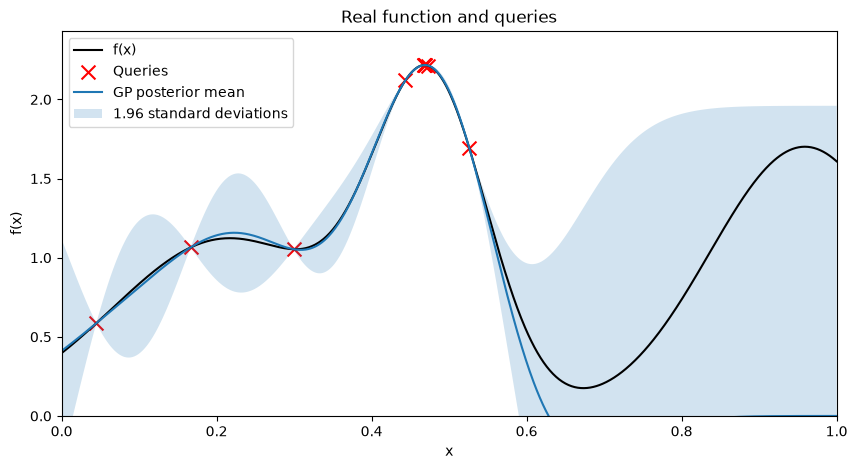

Maximum by grid search: 2.217291939914557
Best observed output: 2.2173004482488303


In [ ]:
real_noise_std = 1e-5
noise_assumption = 1e-5  # GaussianProcessRegressor alpha (observation-noise variance)
rbf_lengthscale = 0.1
beta = 1.96


def calc_function(x):
    exp = -(x - means) ** 2 / std
    return np.sum(amps * np.exp(exp))


kernel = RBF(length_scale=rbf_lengthscale, length_scale_bounds="fixed")
model = GaussianProcessRegressor(
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=CONFIG["normalize_y"],
    n_restarts_optimizer=CONFIG["n_restarts_optimizer"],
    random_state=CONFIG["random_state"],
)

X, Y = [], []
max_obs = -np.inf
num_queries = 10
candidate_rng = np.random.default_rng(CONFIG["random_state"])

for i in range(num_queries):
    if not X:
        x_query = candidate_rng.uniform(0, 1)
    else:
        model.fit(np.asarray(X).reshape(-1, 1), np.asarray(Y))
        acquisition_grid = candidate_rng.integers(
            0,
            1_000_000,
            size=(CONFIG["candidates"], 1),
        ) / 1_000_000
        used = np.asarray(X, dtype=float).reshape(-1, 1)
        unused = ~np.any(
            np.all(acquisition_grid[:, None, :] == used[None, :, :], axis=2),
            axis=1,
        )
        acquisition_grid = acquisition_grid[unused]
        post_mean, post_std = model.predict(acquisition_grid, return_std=True)
        acquisition = post_mean + beta * post_std
        x_query = acquisition_grid[np.argmax(acquisition), 0]

    y_query = calc_function(x_query)  # + np.random.normal(scale=real_noise_std)
    previous_best = max_obs
    X.append(x_query)
    Y.append(y_query)
    max_obs = max(max_obs, y_query)

    delta = y_query - previous_best if np.isfinite(previous_best) else float("nan")
    print(f"(x, y, y_best) = ({x_query:.4f}, {y_query:.4f}, {max_obs:.4f})")
    print(f"delta from previous best = {delta:.4f}")

# Evaluate the function and fit the final GP.
x_grid = np.linspace(0, 1, 1001)
y_real = np.array([calc_function(value) for value in x_grid])
best_obs_grid = np.max(y_real)

model.fit(np.asarray(X).reshape(-1, 1), np.asarray(Y))
post_mean, post_std = model.predict(x_grid.reshape(-1, 1), return_std=True)

plot_optimization_curves(x_grid, y_real, X, Y, post_mean, post_std, beta)

print("Maximum by grid search:", best_obs_grid)
print("Best observed output:", max_obs)

Candidate: 0.773956
Candidate: 0.040645
Candidate: 0.265809
Candidate: 0.458904
Candidate: 0.537993
Candidate: 0.406885
Candidate: 0.999518
Candidate: 0.471234
Candidate: 0.468927
Best observed: [0.468927] 2.2172529198224193


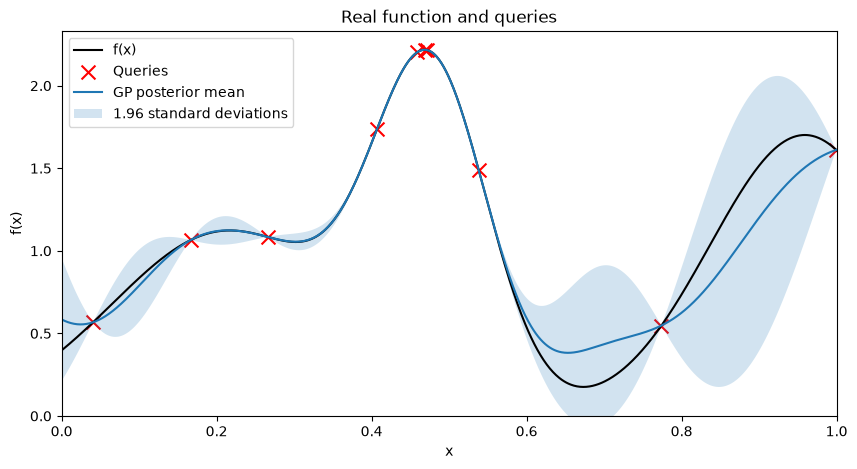

Maximum by grid search: 2.217291939914557
Best observed output: 2.2172529198224193


In [ ]:
from bayesian_bbo import BayesianOptimizer, Observations, OptimisationConfig, format_submission
from bayesian_bbo.surrogate import fit_surrogate

observations = Observations(
    inputs=np.asarray(X[0], dtype=float).reshape(1, 1),
    outputs=np.asarray([Y[0]], dtype=float),
    dimension=1,
)

num_queries = 10
optimizer = BayesianOptimizer(
    observations,
    OptimisationConfig(
        budget=max(0, num_queries - len(observations.inputs)),
        seed=CONFIG["random_state"],
        acquisition="ucb",
        kappa=beta,
        kernel=kernel,
    ),
)

while optimizer.remaining:
    point = optimizer.suggest()
    print('Candidate:', format_submission(point))
    observed_value = calc_function(point)
    optimizer.observe(point, observed_value)

history = optimizer.history
print('Best observed:', history.best_input, history.best_output)

x_grid = np.linspace(0, 1, 1001).reshape(-1, 1)
y_real = np.array([calc_function(value[0]) for value in x_grid])
best_obs_grid = np.max(y_real)

model = fit_surrogate(history, kernel=kernel)
post_mean, post_std = model.predict(x_grid, return_std=True)

plot_optimization_curves(
    x_grid,
    y_real,
    history.inputs,
    history.outputs,
    post_mean,
    post_std,
    beta,
)

print("Maximum by grid search:", best_obs_grid)
print("Best observed output:", history.best_output)

In [ ]:
root = Path('../../data')
function_id = 1
observations = load_observations(root, function_id)